# Homework 4 — Evaluation Metrics for Classification

Machine Learning Zoomcamp 2026 · 2026 lead-scoring release

This notebook evaluates a logistic regression classifier using feature ROC AUC,
validation ROC AUC, precision, recall, F1, and 5-fold cross-validation.
The target is `converted`.

In [3]:
from pathlib import Path
import hashlib
import json
import platform
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split, KFold

np.random.seed(1)
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 120)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})

BASE = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
OUTPUT = BASE / 'outputs'
OUTPUT.mkdir(exist_ok=True)
print(f'Python {platform.python_version()} | NumPy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}')

Python 3.11.9 | NumPy 2.3.5 | pandas 2.2.3 | scikit-learn 1.8.0


## Data preparation

The bundled CSV is checked against the SHA-256 published in the course data README.
If it is absent, the same release is downloaded from a fixed repository commit.
Categorical missing values become the literal string `NA`; numerical missing
values become `0.0`. Constant replacements do not estimate statistics from the data.

In [4]:
DATA_URL = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/f890391cf579ddf20decf9c67766b4a27e0b8ae1/cohorts/2026/data/course_lead_scoring_2026.csv'
EXPECTED_SHA256 = '2d9da196bdefd2a45aa0a17ca21c19f06a5d9d56af628be1f04bbb3531cc12e9'
data_path = BASE / 'course_lead_scoring_2026.csv'
if not data_path.exists():
    data_path.write_bytes(urllib.request.urlopen(DATA_URL, timeout=60).read())
actual_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert actual_sha256 == EXPECTED_SHA256, 'Dataset differs from the pinned 2026 release.'

df = pd.read_csv(data_path)
print('Dataset shape:', df.shape)
print('Missing values before preparation:')
print(df.isna().sum().to_string())

target = 'converted'
categorical = df.drop(columns=target).select_dtypes(include='object').columns.tolist()
numerical = df.drop(columns=target).select_dtypes(include='number').columns.tolist()
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)
assert not df.isna().any().any()
assert set(df[target].unique()) == {0, 1}
print('Categorical features:', categorical)
print('Numerical features:', numerical)

Dataset shape: (5000, 9)
Missing values before preparation:
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
Categorical features: ['lead_source', 'industry', 'employment_status', 'location']
Numerical features: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


In [5]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

assert (len(df_train), len(df_val), len(df_test)) == (3000, 1000, 1000)
assert set(df_train.index).isdisjoint(df_val.index)
assert set(df_full_train.index).isdisjoint(df_test.index)

features = categorical + numerical
y_train = df_train[target].to_numpy()
y_val = df_val[target].to_numpy()
print(f'Train: {len(df_train)} | Validation: {len(df_val)} | Test: {len(df_test)}')

Train: 3000 | Validation: 1000 | Test: 1000


## Question 1 — ROC AUC feature importance

Treat each numerical feature as a prediction score on the training set. If its
AUC is below 0.5, negate the feature and recompute its AUC. This measures the
feature's standalone ability to rank converted leads above other leads; it is
not a measure of its contribution inside the fitted multivariate model.

In [6]:
feature_rows = []
for column in numerical:
    raw_auc = roc_auc_score(y_train, df_train[column])
    inverted = raw_auc < 0.5
    scores = -df_train[column] if inverted else df_train[column]
    feature_rows.append({
        'feature': column,
        'raw_auc': raw_auc,
        'inverted': inverted,
        'auc': roc_auc_score(y_train, scores),
    })

feature_auc = pd.DataFrame(feature_rows).sort_values('auc', ascending=False).reset_index(drop=True)
q1 = feature_auc.loc[0, 'feature']
print(feature_auc.to_string(index=False, float_format=lambda x: f'{x:.6f}'))
print('Answer Q1:', q1)

                 feature  raw_auc  inverted      auc
              lead_score 0.788225     False 0.788225
       interaction_count 0.764920     False 0.764920
number_of_courses_viewed 0.722989     False 0.722989
           annual_income 0.608198     False 0.608198
Answer Q1: lead_score


## Question 2 — Train logistic regression and evaluate ROC AUC

Fit `DictVectorizer` on training records only. Categorical values become one-hot
features; numerical values remain numerical. Transform validation records with
the same vectorizer. ROC AUC uses probabilities, rather than binary predictions.

In [7]:
def train_model(frame, C=1.0):
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(frame[features].to_dict(orient='records'))
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, frame[target].to_numpy())
    return dv, model

def predict(frame, dv, model):
    X = dv.transform(frame[features].to_dict(orient='records'))
    return model.predict_proba(X)[:, 1]

dv, model = train_model(df_train)
y_pred = predict(df_val, dv, model)
validation_auc = roc_auc_score(y_val, y_pred)
q2 = round(validation_auc, 3)
print(f'Validation ROC AUC: {validation_auc:.9f}')
print(f'Answer Q2: {q2:.3f}')

Validation ROC AUC: 0.731822229
Answer Q2: 0.732


## Question 3 — Precision and recall

Evaluate all 101 thresholds from 0.00 through 1.00. Predict conversion when
`probability >= threshold`. Use `zero_division=0` when no positive prediction is
made. Exclude thresholds where both precision and recall equal zero, then choose
the smallest absolute difference. The grid need not contain an exact intersection.

threshold             0.630000
precision             0.732759
recall                0.725256
f1                    0.728988
absolute_difference   0.007503
Answer Q3: 0.63


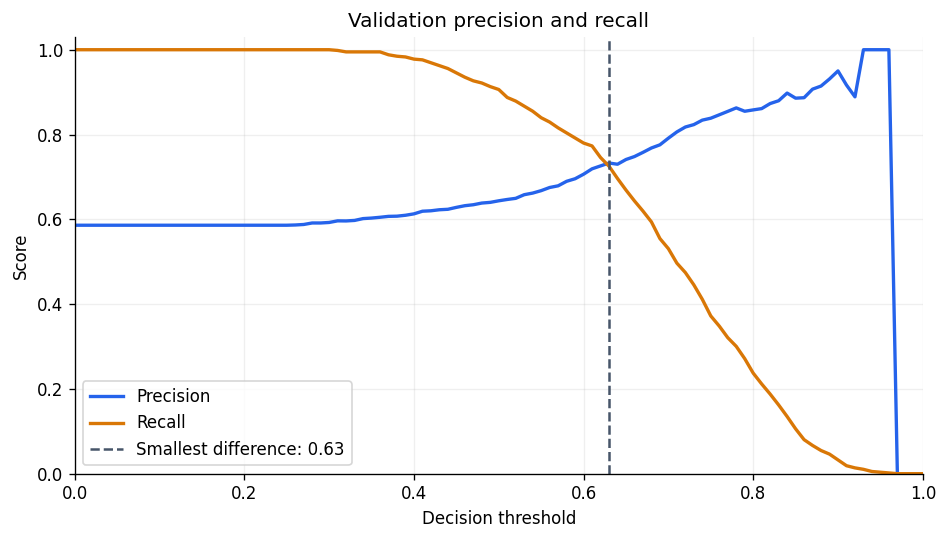

In [8]:
thresholds = np.arange(101) / 100
metric_rows = []
for threshold in thresholds:
    predicted = y_pred >= threshold
    metric_rows.append({
        'threshold': threshold,
        'precision': precision_score(y_val, predicted, zero_division=0),
        'recall': recall_score(y_val, predicted, zero_division=0),
        'f1': f1_score(y_val, predicted, zero_division=0),
    })

metrics = pd.DataFrame(metric_rows)
metrics['absolute_difference'] = (metrics['precision'] - metrics['recall']).abs()
eligible = metrics[(metrics['precision'] != 0) | (metrics['recall'] != 0)]
intersection = eligible.loc[eligible['absolute_difference'].idxmin()]
q3 = float(intersection['threshold'])
print(intersection.to_string(float_format=lambda x: f'{x:.6f}'))
print(f'Answer Q3: {q3:.2f}')

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(metrics['threshold'], metrics['precision'], label='Precision', color='#2563eb', linewidth=2)
ax.plot(metrics['threshold'], metrics['recall'], label='Recall', color='#d97706', linewidth=2)
ax.axvline(q3, color='#475569', linestyle='--', label=f'Smallest difference: {q3:.2f}')
ax.set(xlabel='Decision threshold', ylabel='Score', title='Validation precision and recall', xlim=(0, 1), ylim=(0, 1.03))
ax.legend(loc='lower left')
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT / 'precision_recall.png', dpi=160)
plt.show()

## Question 4 — Maximize F1

The correctly formatted formula is $F_1 = 2PR/(P+R)$, with a value of zero when
both terms are zero. Select the threshold that maximizes F1 on the same grid.
If several thresholds tie, select the first, which is the smallest threshold.

threshold   0.410000
precision   0.619048
recall      0.976109
f1          0.757616
Answer Q4: 0.41


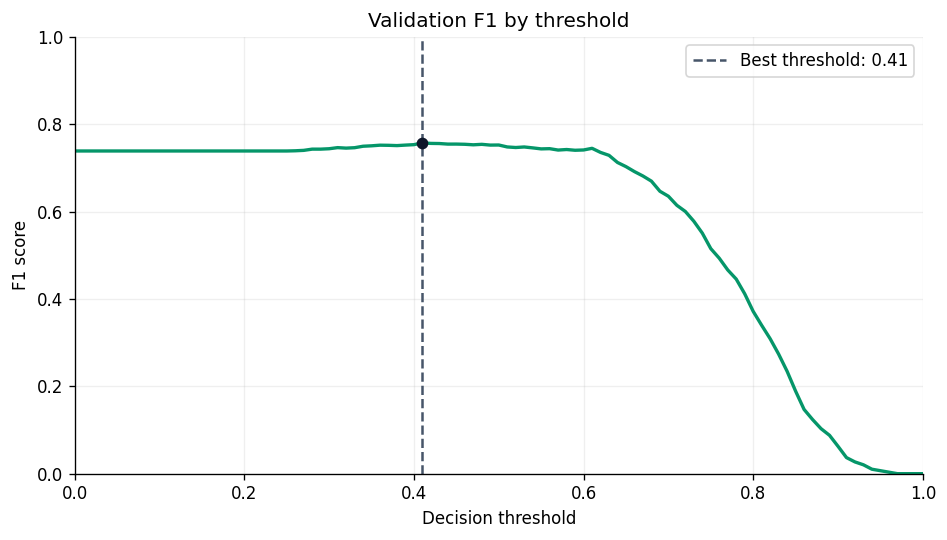

In [9]:
best_f1 = metrics.loc[metrics['f1'].idxmax()]
q4 = float(best_f1['threshold'])
print(best_f1[['threshold', 'precision', 'recall', 'f1']].to_string(float_format=lambda x: f'{x:.6f}'))
print(f'Answer Q4: {q4:.2f}')

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(metrics['threshold'], metrics['f1'], color='#059669', linewidth=2)
ax.scatter([q4], [best_f1['f1']], color='#0f172a', zorder=3)
ax.axvline(q4, color='#475569', linestyle='--', label=f'Best threshold: {q4:.2f}')
ax.set(xlabel='Decision threshold', ylabel='F1 score', title='Validation F1 by threshold', xlim=(0, 1), ylim=(0, 1))
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT / 'f1.png', dpi=160)
plt.show()

## Question 5 — Five-fold cross-validation

Use the 4,000 rows of `df_full_train`. Each fold fits a fresh vectorizer and model
on its 3,200 training rows, then evaluates on its 800 validation rows. The test
set is not involved. Calculate the standard deviation with `np.std` (`ddof=0`).

In [10]:
def cross_validate(C):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        fold_train = df_full_train.iloc[train_idx]
        fold_val = df_full_train.iloc[val_idx]
        fold_dv, fold_model = train_model(fold_train, C=C)
        fold_pred = predict(fold_val, fold_dv, fold_model)
        scores.append(roc_auc_score(fold_val[target], fold_pred))
    return np.array(scores)

cv_scores = cross_validate(C=1.0)
cv_std = float(np.std(cv_scores, ddof=0))
q5 = round(cv_std, 3)
print(pd.DataFrame({'fold': range(1, 6), 'roc_auc': cv_scores}).to_string(index=False))
print(f'Mean ROC AUC: {cv_scores.mean():.9f}')
print(f'Standard deviation: {cv_std:.9f}')
print(f'Answer Q5: {q5:.3f}')

 fold  roc_auc
    1 0.730560
    2 0.729573
    3 0.736343
    4 0.741245
    5 0.720914
Mean ROC AUC: 0.731726971
Standard deviation: 0.006853233
Answer Q5: 0.007


## Question 6 — Tune C

Compare `C` values using the same five folds. Larger `C` means weaker
regularization. Rank the rounded mean ROC AUC from highest to lowest; break ties
using the rounded standard deviation from lowest to highest, and finally the
smallest `C`. Reuse the already computed scores for `C=1`.

In [11]:
tuning_rows = []
all_cv_scores = {}
for C in [0.000001, 0.001, 1.0]:
    scores = cv_scores if C == 1.0 else cross_validate(C)
    all_cv_scores[str(C)] = scores.tolist()
    tuning_rows.append({
        'C': C,
        'mean_auc': float(scores.mean()),
        'std_auc': float(scores.std(ddof=0)),
        'mean_rounded': round(float(scores.mean()), 3),
        'std_rounded': round(float(scores.std(ddof=0)), 3),
    })

tuning = pd.DataFrame(tuning_rows)
ranked = tuning.sort_values(['mean_rounded', 'std_rounded', 'C'], ascending=[False, True, True])
q6 = float(ranked.iloc[0]['C'])
print(tuning.to_string(index=False, float_format=lambda x: f'{x:.6f}'))
print(f'Answer Q6: C = {q6:g}')

       C  mean_auc  std_auc  mean_rounded  std_rounded
0.000001  0.616734 0.018670      0.617000     0.019000
0.001000  0.749172 0.009996      0.749000     0.010000
1.000000  0.731727 0.006853      0.732000     0.007000
Answer Q6: C = 0.001


## Answers and interpretation

- **Q1:** `lead_score` has the highest standalone training ROC AUC.
- **Q2:** Validation ROC AUC is **0.732**.
- **Q3:** Precision and recall have the smallest nonzero absolute difference at **0.63**.
- **Q4:** F1 is maximal at **0.41**.
- **Q5:** Five-fold ROC AUC standard deviation is **0.007**.
- **Q6:** **C = 0.001** has the best rounded mean ROC AUC.

The precision/recall intersection and the F1 maximum are different objectives,
so their best thresholds can differ. AUC evaluates ranking across thresholds;
precision, recall, and F1 describe decisions at a particular threshold.
These validation-selected thresholds have not been evaluated on the held-out test set.

In [12]:
answers = {'q1': q1, 'q2': q2, 'q3': q3, 'q4': q4, 'q5': q5, 'q6': q6}
expected = {'q1': 'lead_score', 'q2': 0.732, 'q3': 0.63, 'q4': 0.41, 'q5': 0.007, 'q6': 0.001}
assert answers == expected, f'Results differ from the verified answer choices: {answers}'

results = {
    'answers': answers,
    'dataset_sha256': actual_sha256,
    'dataset_url': DATA_URL,
    'versions': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'scikit-learn': sklearn.__version__},
    'split_sizes': {'train': len(df_train), 'validation': len(df_val), 'test': len(df_test)},
    'feature_auc': feature_auc.to_dict(orient='records'),
    'validation_auc': float(validation_auc),
    'precision_recall_selection': intersection.to_dict(),
    'f1_selection': best_f1.to_dict(),
    'cv_scores': all_cv_scores,
    'tuning': tuning.to_dict(orient='records'),
}
(OUTPUT / 'results.json').write_text(json.dumps(results, indent=2), encoding='utf-8')
metrics.to_csv(OUTPUT / 'threshold_metrics.csv', index=False)
tuning.to_csv(OUTPUT / 'cv_tuning.csv', index=False)
print(json.dumps(answers, indent=2))

{
  "q1": "lead_score",
  "q2": 0.732,
  "q3": 0.63,
  "q4": 0.41,
  "q5": 0.007,
  "q6": 0.001
}
